# uCDCR Dataset Exploration

Explore the [AnZhu/uCDCR](https://huggingface.co/datasets/AnZhu/uCDCR) dataset to understand its structure,
chain-size distributions, and implications for MS Loss with PK sampling.

In [1]:
import pandas as pd
import numpy as np
from datasets import load_dataset
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)

/home/ubuntu/github/CDCR_lexical_diversity/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load the dataset

In [2]:
# load_dataset("AnZhu/uCDCR") fails because FCC has mismatched columns.
# Instead, we download individual parquet files per dataset using hf_hub_download.
# Each dataset folder contains:
#   - all_mentions.parquet  (always present)
#   - all_documents.parquet (present for most datasets, not all)
#   - train/val/test folders with entity_mentions.json + event_mentions.json

from huggingface_hub import hf_hub_download

REPO_ID = "AnZhu/uCDCR"
DATASETS = [
    "CD2CR", "CEREC", "ECBplus", "ECBplusMETAm", "FCC", "GVC",
    "HyperCoref", "MEANTIME", "NIdent", "NP4E", "NewsWCL50", "WECEng"
]

# Download all_mentions.parquet for each dataset
mention_dfs = {}
for name in DATASETS:
    try:
        path = hf_hub_download(
            repo_id=REPO_ID,
            filename=f"{name}/all_mentions.parquet",
            repo_type="dataset",
        )
        df = pd.read_parquet(path)
        df["dataset"] = name
        mention_dfs[name] = df
        print(f"{name:20s}  mentions: {len(df):>8,}  cols: {len(df.columns)}")
    except Exception as e:
        print(f"{name:20s}  FAILED: {e}")

print(f"\nLoaded mentions for {len(mention_dfs)} / {len(DATASETS)} datasets")

# Download all_documents.parquet where available
doc_dfs = {}
for name in DATASETS:
    try:
        path = hf_hub_download(
            repo_id=REPO_ID,
            filename=f"{name}/all_documents.parquet",
            repo_type="dataset",
        )
        df = pd.read_parquet(path)
        df["dataset"] = name
        doc_dfs[name] = df
        print(f"{name:20s}  documents parquet: {len(df):>10,} rows")
    except Exception as e:
        print(f"{name:20s}  no documents parquet ({type(e).__name__})")

print(f"\nLoaded documents for {len(doc_dfs)} / {len(DATASETS)} datasets")

CD2CR                 mentions:    7,597  cols: 30
CEREC                 mentions:    7,080  cols: 30


ECBplus               mentions:   15,051  cols: 30
ECBplusMETAm          mentions:    6,348  cols: 30
FCC                   mentions:    3,561  cols: 30
GVC                   mentions:    7,284  cols: 30
HyperCoref            mentions:   60,401  cols: 30
MEANTIME              mentions:    6,506  cols: 30
NIdent                mentions:   12,988  cols: 30
NP4E                  mentions:    6,559  cols: 30
NewsWCL50             mentions:    6,531  cols: 30
WECEng                mentions:   43,672  cols: 30

Loaded mentions for 12 / 12 datasets
CD2CR                 documents parquet:     86,601 rows
CEREC                 documents parquet:     62,341 rows
ECBplus               documents parquet:    627,829 rows
ECBplusMETAm          documents parquet:    184,430 rows
FCC                   no documents parquet (RemoteEntryNotFoundError)
GVC                   documents parquet:    185,655 rows
HyperCoref            no documents parquet (RemoteEntryNotFoundError)
MEANTIME              docum

In [3]:
# Combine all mentions into a single DataFrame
all_mentions = pd.concat(mention_dfs.values(), ignore_index=True)
print(f"Total mentions: {len(all_mentions):,}")
print(f"Columns ({len(all_mentions.columns)}): {all_mentions.columns.tolist()}")

# Combine all documents (where available)
all_documents = pd.concat(doc_dfs.values(), ignore_index=True)
print(f"\nTotal document tokens: {len(all_documents):,}")
print(f"From {len(doc_dfs)} datasets: {list(doc_dfs.keys())}")

Total mentions: 183,578
Columns (30): ['coref_chain', 'mention_id', 'tokens_str', 'description', 'coref_type', 'mention_type', 'mention_full_type', 'tokens_text', 'tokens_number', 'mention_head', 'mention_head_id', 'mention_head_pos', 'mention_head_lemma', 'mention_ner', 'sent_id', 'topic', 'topic_id', 'subtopic_id', 'subtopic', 'doc_id', 'doc', 'mention_context', 'context_start_end_global_id', 'mention_sentence_start_end', 'tokens_number_context', 'mention_head_id_context', 'is_singleton', 'conll_doc_key', 'split', 'dataset']

Total document tokens: 6,355,936
From 9 datasets: ['CD2CR', 'CEREC', 'ECBplus', 'ECBplusMETAm', 'GVC', 'MEANTIME', 'NIdent', 'NP4E', 'WECEng']


## 2. Schema & sample records

In [4]:
all_mentions.dtypes

coref_chain                    object
mention_id                     object
tokens_str                     object
description                    object
coref_type                     object
mention_type                   object
mention_full_type              object
tokens_text                    object
tokens_number                  object
mention_head                   object
mention_head_id                 int64
mention_head_pos               object
mention_head_lemma             object
mention_ner                    object
sent_id                         int64
topic                          object
topic_id                       object
subtopic_id                    object
subtopic                       object
doc_id                         object
doc                            object
mention_context                object
context_start_end_global_id    object
mention_sentence_start_end     object
tokens_number_context          object
mention_head_id_context         int64
is_singleton

In [5]:
all_mentions.sample(3, random_state=42).T

,131474,164686,116861
coref_chain,OTHmofwfmUDsvJBFn8G959Tj7,12554_2004_Indian_Ocean_earthquake_,1_china_208
mention_id,NP4E_XC9ayGrwqxLZSxw86ntKQX,WECEng_10663,GNynHksDKGmi25rmQdUy7F
tokens_str,armed men calling themselves MRTA rebels,Asian tsunami in December 2004,prison
description,armed men calling themselves MRTA rebels,2004 Indian Ocean earthquake and tsunami,prison
coref_type,IDENTITY,IDENTITY,IDENTITY
mention_type,OTH,EVE,OTH
mention_full_type,OTHER,EVENT,OTHER
tokens_text,"['armed', 'men', 'calling', 'themselves', 'MRTA', 'rebels']","['Asian', 'tsunami', 'in', 'December', '2004']",['prison']
tokens_number,"[3, 4, 5, 6, 7, 8]","[19, 20, 21, 22, 23]",[12]
mention_head,men,tsunami,prison


## 3. High-level dataset statistics

In [6]:
summary = all_mentions.groupby("dataset").agg(
    mentions=("mention_id", "count"),
    chains=("coref_chain", "nunique"),
    singletons=("is_singleton", "sum"),
    topics=("topic", "nunique"),
    subtopics=("subtopic", "nunique"),
    documents=("doc_id", "nunique"),
).assign(
    avg_chain_size=lambda d: d["mentions"] / d["chains"],
    singleton_pct=lambda d: (d["singletons"] / d["mentions"] * 100).round(1),
)

# Add totals row
totals = summary.sum(numeric_only=True)
totals["avg_chain_size"] = totals["mentions"] / totals["chains"]
totals["singleton_pct"] = (totals["singletons"] / totals["mentions"] * 100).round(1)
summary.loc["TOTAL"] = totals

summary[["mentions", "chains", "singletons", "singleton_pct", "avg_chain_size",
         "topics", "subtopics", "documents"]]

,mentions,chains,singletons,singleton_pct,avg_chain_size,topics,subtopics,documents
dataset,,,,,,,,
CD2CR,7597.0,5222.0,4496.0,59.2,1.454807,1.0,264.0,527.0
CEREC,7080.0,1475.0,486.0,6.9,4.800000,1.0,77.0,456.0
ECBplus,15051.0,4952.0,3445.0,22.9,3.039378,43.0,85.0,22.0
ECBplusMETAm,6348.0,2095.0,1481.0,23.3,3.030072,18.0,36.0,19.0
FCC,3561.0,469.0,254.0,7.1,7.592751,1.0,183.0,428.0
GVC,7284.0,1679.0,635.0,8.7,4.338297,1.0,241.0,510.0
HyperCoref,60401.0,13102.0,5869.0,9.7,4.610060,35.0,324.0,40938.0
MEANTIME,6506.0,2938.0,2270.0,34.9,2.214432,4.0,120.0,120.0
NIdent,12988.0,2463.0,1275.0,9.8,5.273244,1.0,5.0,93.0


## 4. Split distribution

In [7]:
# Mentions per dataset per split
split_counts = all_mentions.groupby(["dataset", "split"]).size().unstack(fill_value=0)
split_counts["total"] = split_counts.sum(axis=1)
split_counts

split,test,train,val,total
dataset,,,,
CD2CR,1175,4602,1820,7597
CEREC,1267,3719,2094,7080
ECBplus,3820,8521,2710,15051
ECBplusMETAm,3729,0,2619,6348
FCC,1208,1603,750,3561
GVC,1008,5299,977,7284
HyperCoref,4759,49777,5865,60401
MEANTIME,1256,3355,1895,6506
NIdent,2630,7178,3180,12988


## 5. Coreference chain size distribution

This is the critical analysis for PK sampling. We need to understand how many
mentions each chain has — chains with only 1 member (singletons) can't form
positive pairs, and chains with 2 members are the minimum for K=2.

In [8]:
# Compute chain sizes (globally unique chain = dataset + coref_chain)
chain_sizes = (
    all_mentions
    .groupby(["dataset", "coref_chain"])
    .size()
    .reset_index(name="chain_size")
)

print(f"Total unique chains: {len(chain_sizes):,}")
print(f"\nChain size distribution (all datasets):")
print(chain_sizes["chain_size"].describe().to_string())
print(f"\nChain size percentiles:")
for p in [50, 75, 90, 95, 99]:
    print(f"  {p}th: {chain_sizes['chain_size'].quantile(p/100):.0f}")

Total unique chains: 43,092

Chain size distribution (all datasets):
count    43092.000000
mean         4.260141
std          9.154353
min          1.000000
25%          1.000000
50%          2.000000
75%          4.000000
max        391.000000

Chain size percentiles:
  50th: 2
  75th: 4
  90th: 10
  95th: 15
  99th: 31


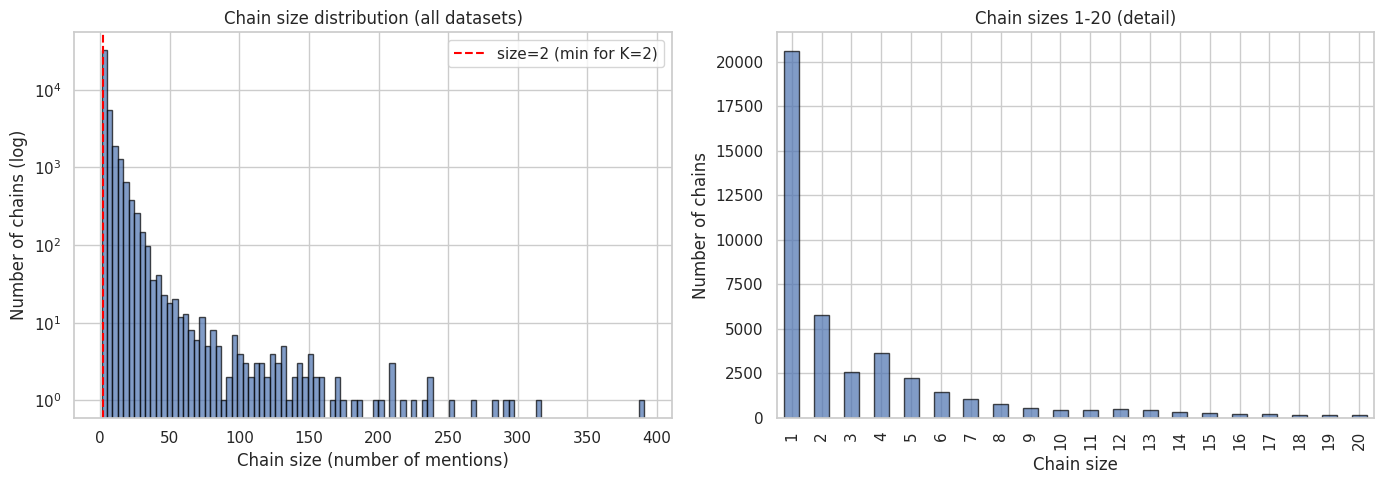

In [9]:
# Histogram of chain sizes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: full distribution (log scale)
ax = axes[0]
chain_sizes["chain_size"].hist(bins=100, ax=ax, edgecolor="black", alpha=0.7)
ax.set_yscale("log")
ax.set_xlabel("Chain size (number of mentions)")
ax.set_ylabel("Number of chains (log)")
ax.set_title("Chain size distribution (all datasets)")
ax.axvline(x=2, color="red", linestyle="--", label="size=2 (min for K=2)")
ax.legend()

# Right: zoomed in to size <= 20
ax = axes[1]
small_chains = chain_sizes[chain_sizes["chain_size"] <= 20]
small_chains["chain_size"].value_counts().sort_index().plot.bar(ax=ax, edgecolor="black", alpha=0.7)
ax.set_xlabel("Chain size")
ax.set_ylabel("Number of chains")
ax.set_title("Chain sizes 1-20 (detail)")

plt.tight_layout()
plt.show()

In [10]:
# Chain size buckets — what fraction of chains can support K=2, K=3, K=4?
buckets = pd.cut(
    chain_sizes["chain_size"],
    bins=[0, 1, 2, 3, 4, 5, 10, 20, 50, float("inf")],
    labels=["1 (singleton)", "2", "3", "4", "5", "6-10", "11-20", "21-50", "50+"]
)
bucket_counts = buckets.value_counts().sort_index()
bucket_pct = (bucket_counts / len(chain_sizes) * 100).round(1)

bucket_df = pd.DataFrame({"chains": bucket_counts, "pct": bucket_pct})
bucket_df["cumulative_pct"] = bucket_df["pct"].cumsum()
bucket_df

,chains,pct,cumulative_pct
chain_size,,,
1 (singleton),20634,47.9,47.9
2,5783,13.4,61.3
3,2592,6.0,67.3
4,3629,8.4,75.7
5,2213,5.1,80.8
6-10,4216,9.8,90.6
11-20,2850,6.6,97.2
21-50,1005,2.3,99.5
50+,170,0.4,99.9


In [11]:
# Chain size distribution PER DATASET
chain_size_by_ds = (
    chain_sizes
    .groupby("dataset")["chain_size"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .round(2)
    .rename(columns={"count": "n_chains"})
)

# Add: fraction of chains with size >= 2 (usable for PK sampling)
usable = chain_sizes[chain_sizes["chain_size"] >= 2].groupby("dataset").size()
chain_size_by_ds["chains_ge2"] = usable
chain_size_by_ds["pct_ge2"] = (chain_size_by_ds["chains_ge2"] / chain_size_by_ds["n_chains"] * 100).round(1)

chain_size_by_ds

,n_chains,mean,median,min,max,std,chains_ge2,pct_ge2
dataset,,,,,,,,
CD2CR,5222,1.45,1.0,1,37,2.09,726,13.9
CEREC,1475,4.80,2.0,1,60,5.99,989,67.1
ECBplus,4952,3.04,1.0,1,81,5.68,1507,30.4
ECBplusMETAm,2095,3.03,1.0,1,74,5.71,614,29.3
FCC,469,7.59,2.0,1,297,23.93,284,60.6
GVC,1679,4.34,2.0,1,78,5.09,1044,62.2
HyperCoref,13102,4.61,2.0,1,64,5.63,7692,58.7
MEANTIME,2938,2.21,1.0,1,270,9.30,684,23.3
NIdent,2463,5.27,1.0,1,315,18.45,1188,48.2


## 6. Chain sizes within train split only

For MS Loss training, we only sample from the train split.
Let's see the chain size distribution restricted to train mentions.

In [12]:
train_mentions = all_mentions[all_mentions["split"] == "train"].copy()
print(f"Train mentions: {len(train_mentions):,}")

train_chain_sizes = (
    train_mentions
    .groupby(["dataset", "coref_chain"])
    .size()
    .reset_index(name="chain_size")
)

print(f"Train chains: {len(train_chain_sizes):,}")
print(f"\nTrain chain size distribution:")
print(train_chain_sizes["chain_size"].describe().to_string())

# Buckets for train
train_buckets = pd.cut(
    train_chain_sizes["chain_size"],
    bins=[0, 1, 2, 3, 4, 5, 10, 20, 50, float("inf")],
    labels=["1 (singleton)", "2", "3", "4", "5", "6-10", "11-20", "21-50", "50+"]
)
train_bucket_counts = train_buckets.value_counts().sort_index()
train_bucket_pct = (train_bucket_counts / len(train_chain_sizes) * 100).round(1)

train_bucket_df = pd.DataFrame({"chains": train_bucket_counts, "pct": train_bucket_pct})
train_bucket_df["cumulative_pct"] = train_bucket_df["pct"].cumsum()
train_bucket_df

Train mentions: 127,958
Train chains: 23,887

Train chain size distribution:
count    23887.000000
mean         5.356805
std          9.074210
min          1.000000
25%          1.000000
50%          3.000000
75%          6.000000
max        391.000000


,chains,pct,cumulative_pct
chain_size,,,
1 (singleton),8070,33.8,33.8
2,2768,11.6,45.4
3,1529,6.4,51.8
4,3036,12.7,64.5
5,1867,7.8,72.3
6-10,3412,14.3,86.6
11-20,2390,10.0,96.6
21-50,732,3.1,99.7
50+,83,0.3,100.0


In [13]:
# Per-dataset train chain stats
train_chain_by_ds = (
    train_chain_sizes
    .groupby("dataset")["chain_size"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
    .rename(columns={"count": "n_chains"})
)

# Usable chains (size >= 2)
train_usable = train_chain_sizes[train_chain_sizes["chain_size"] >= 2].groupby("dataset").size()
train_chain_by_ds["chains_ge2"] = train_usable
train_chain_by_ds["pct_ge2"] = (train_chain_by_ds["chains_ge2"] / train_chain_by_ds["n_chains"] * 100).round(1)

# Total mentions in train per dataset
train_mention_counts = train_mentions.groupby("dataset").size()
train_chain_by_ds["n_mentions"] = train_mention_counts

train_chain_by_ds[["n_mentions", "n_chains", "chains_ge2", "pct_ge2", "mean", "median", "min", "max"]]

,n_mentions,n_chains,chains_ge2,pct_ge2,mean,median,min,max
dataset,,,,,,,,
CD2CR,4602,3221,426,13.2,1.43,1.0,1,37
CEREC,3719,750,535,71.3,4.96,3.0,1,60
ECBplus,8521,2810,877,31.2,3.03,1.0,1,81
FCC,1603,259,151,58.3,6.19,2.0,1,281
GVC,5299,1158,737,63.6,4.58,3.0,1,78
HyperCoref,49777,5477,5477,100.0,9.09,6.0,3,64
MEANTIME,3355,1522,374,24.6,2.20,1.0,1,208
NIdent,7178,1316,698,53.0,5.45,2.0,1,208
NP4E,3375,332,332,100.0,10.17,3.5,2,184


## 7. Mention context inspection

Verify that `mention_context` + `tokens_number_context` can be used to
insert `[E]`/`[/E]` markers, replacing Pipeline 01's string representation step.

In [14]:
# Pick a non-singleton mention and show its context with markers
sample = all_mentions[~all_mentions["is_singleton"]].sample(1, random_state=42).iloc[0]

print(f"Dataset:      {sample['dataset']}")
print(f"Mention ID:   {sample['mention_id']}")
print(f"Coref chain:  {sample['coref_chain']}")
print(f"Tokens:       {sample['tokens_str']}")
print(f"Sent ID:      {sample['sent_id']}")
print(f"Doc ID:       {sample['doc_id']}")
print(f"Topic:        {sample['topic']}")
print(f"Subtopic:     {sample['subtopic']}")
print(f"Singleton:    {sample['is_singleton']}")
print()

# Reconstruct context with [E] / [/E] markers
context_tokens = list(sample["mention_context"])
mention_positions = list(sample["tokens_number_context"])

print(f"Context length: {len(context_tokens)} tokens")
print(f"Mention positions in context: {mention_positions}")
print()

# Insert markers
marked_tokens = context_tokens.copy()
# Insert [/E] first (higher index) to avoid shifting
end_pos = mention_positions[-1]
start_pos = mention_positions[0]
marked_tokens.insert(end_pos + 1, "[/E]")
marked_tokens.insert(start_pos, "[E]")

print("Context with markers:")
print(" ".join(marked_tokens))

Dataset:      GVC
Mention ID:   3rGA3NGYS79FLUUFr8sBW5
Coref chain:  1999556993999111999857875
Tokens:       injured
Sent ID:      34
Doc ID:       8a82a70b851c000fd66f5871d2a7c32a
Topic:        0_gun_violence
Subtopic:     556993
Singleton:    False

Context length: 1926 tokens
Mention positions in context: ['[', '1', '1', '4', ']']



TypeError: can only concatenate str (not "int") to str

In [15]:
# Show all mentions in the same coref chain
chain_members = all_mentions[
    (all_mentions["dataset"] == sample["dataset"]) &
    (all_mentions["coref_chain"] == sample["coref_chain"])
][["mention_id", "tokens_str", "doc_id", "sent_id", "split", "is_singleton"]]

print(f"\nCoref chain '{sample['coref_chain']}' has {len(chain_members)} mentions:")
chain_members


Coref chain '1999556993999111999857875' has 40 mentions:


,mention_id,tokens_str,doc_id,sent_id,split,is_singleton
45511,bSohGKtzesTprhnzmR3iQj,deaths,54aafae5ecfb4ea7b63b0feb3cc1f804,2,val,False
45512,WRhgWjZsz7G84BG4LwLecc,incidents,54aafae5ecfb4ea7b63b0feb3cc1f804,4,val,False
45513,CmMjPUX8fEnEuzH6nVuvFY,shot,54aafae5ecfb4ea7b63b0feb3cc1f804,4,val,False
45516,fnrj9Hm7UuZt9CALareE6R,shot,54aafae5ecfb4ea7b63b0feb3cc1f804,5,val,False
45520,5x738hVSDZtpiii4cYBjpn,shot,54aafae5ecfb4ea7b63b0feb3cc1f804,9,val,False
45521,YEqAHCmMRXCsTu6SdbCAXi,shootings,54aafae5ecfb4ea7b63b0feb3cc1f804,12,val,False
45526,V76E4v8CJgnYHUCo46BX8g,shot,54aafae5ecfb4ea7b63b0feb3cc1f804,16,val,False
45527,9JNQBxssCEFS9WzEVzSTpy,incidents,54aafae5ecfb4ea7b63b0feb3cc1f804,17,val,False
45528,A5UiYQ8wk3ZuwCZBL6QQ5A,shot,54aafae5ecfb4ea7b63b0feb3cc1f804,17,val,False
45752,GXtwQAg3LUigr4G6VWZTFy,shooting,8a82a70b851c000fd66f5871d2a7c32a,3,val,False


## 7b. Full documents (`all_documents.parquet`)

The `doc` column in mentions is just a **document ID** (e.g. `"1_10ecb"`), not the text.
Full document text is stored token-by-token in `all_documents.parquet` with columns:
- `token` — the word
- `sent_id`, `token_id`, `token_id_global` — positioning (global IDs map to `context_start_end_global_id` in mentions)
- `whitespace_after` — for reconstructing running text
- `reference` — CoNLL coreference annotations

Not all datasets have this file (README notes FCC, HyperCoref, NewsWCL50 may be missing).

In [16]:
# Check which datasets have all_documents.parquet
print("all_documents.parquet availability and size:")
print("=" * 60)
for name in DATASETS:
    if name in doc_dfs:
        d = doc_dfs[name]
        n_docs = d["topic/subtopic_name/doc"].nunique()
        n_tokens = len(d)
        print(f"{name:20s}  {n_tokens:>10,} token rows  {n_docs:>5,} docs")
    else:
        print(f"{name:20s}  NOT AVAILABLE")

all_documents.parquet availability and size:
CD2CR                     86,601 token rows    528 docs
CEREC                     62,341 token rows    456 docs
ECBplus                  627,829 token rows    982 docs
ECBplusMETAm             184,430 token rows    407 docs
FCC                   NOT AVAILABLE
GVC                      185,655 token rows    510 docs
HyperCoref            NOT AVAILABLE
MEANTIME                  53,004 token rows    120 docs
NIdent                    50,358 token rows     93 docs
NP4E                      51,229 token rows     94 docs
NewsWCL50             NOT AVAILABLE
WECEng                 5,054,489 token rows  37,129 docs


In [17]:
# Reconstruct a full document from all_documents.parquet and show a mention in context
# Pick ECBplus as example
ecb_docs = doc_dfs["ECBplus"]
ecb_mentions = mention_dfs["ECBplus"]

# Pick a mention and find its document
sample_mention = ecb_mentions[~ecb_mentions["is_singleton"]].sample(1, random_state=7).iloc[0]
conll_key = sample_mention["conll_doc_key"]

print(f"Mention:    '{sample_mention['tokens_str']}'")
print(f"Chain:      {sample_mention['coref_chain']}")
print(f"Doc ID:     {sample_mention['doc_id']}")
print(f"conll_key:  {conll_key}")
print(f"Sent ID:    {sample_mention['sent_id']}")
print()

# Get document tokens
doc_tokens = ecb_docs[ecb_docs["topic/subtopic_name/doc"] == conll_key].sort_values("token_id_global")

# Reconstruct full document text
def reconstruct_text(token_df):
    """Join tokens respecting whitespace_after."""
    parts = []
    for _, row in token_df.iterrows():
        parts.append(row["token"])
        if row["whitespace_after"]:
            parts.append(" ")
    return "".join(parts).strip()

full_text = reconstruct_text(doc_tokens)
print(f"Document ({len(doc_tokens)} tokens):")
print("-" * 80)
print(full_text[:1000])
if len(full_text) > 1000:
    print(f"\n... [{len(full_text) - 1000} more chars]")

# Show how mention_context maps to the document via context_start_end_global_id
ctx_start, ctx_end = sample_mention["context_start_end_global_id"]
print(f"\nContext window: global token IDs [{ctx_start}, {ctx_end}]")
context_tokens_from_doc = doc_tokens[
    (doc_tokens["token_id_global"] >= ctx_start) &
    (doc_tokens["token_id_global"] <= ctx_end)
]
context_text = reconstruct_text(context_tokens_from_doc)
print(f"Context from document ({len(context_tokens_from_doc)} tokens):")
print("-" * 80)
print(context_text[:500])

# Compare with mention_context field
mention_ctx_text = " ".join(sample_mention["mention_context"])
print(f"\nmention_context field ({len(sample_mention['mention_context'])} tokens):")
print("-" * 80)
print(mention_ctx_text[:500])

Mention:    'services'
Chain:      ACT16978873923586839
Doc ID:     10
conll_key:  30/30ecbplus/10
Sent ID:    2

Document (291 tokens):
--------------------------------------------------------------------------------
http://mybroadband.co.za / news/broadband/36092-seacom-restored-for-commercial-isps-on-alternate-routes.htmlSeacom restored for commercial ISPs on alternate routesSeacom's business customers, including commercial Internet Service Providers, have had their services restored via alternative routes, Seacom announced todayOctober 14, 2011Subsea cable operator Seacom announced on Twitter today (14 October 2011) that they have restored all their business customers on alternate routes following an outage expected to extend into next week.This includes commercial Internet service providers, according to Seacom's tweet, which said that all such ISPs using Seacom capacity are no longer affected by the outage.Seacom started to experience problems on Saturday, 8 October 2011, which i

ValueError: too many values to unpack (expected 2)

## 8. Mention types and coref types

In [18]:
# Mention types per dataset
print("mention_type values per dataset:")
for ds in sorted(all_mentions["dataset"].unique()):
    types = all_mentions[all_mentions["dataset"] == ds]["mention_type"].value_counts()
    print(f"\n  {ds}: {dict(types)}")

print("\n" + "="*60)
print("\ncoref_type values:")
print(all_mentions["coref_type"].value_counts().to_string())

mention_type values per dataset:

  CD2CR: {'OTH': 6677, 'ORG': 202, 'GPE': 186, 'PER': 158, 'DAT': 152, 'CAR': 125, 'LOC': 44, 'NOR': 20, 'MON': 7, 'QUA': 5, 'PRO': 5, 'FAC': 5, 'ORD': 3, 'LAN': 2, 'EVE': 2, 'LAW': 2, 'TIM': 1, 'WOR': 1}

  CEREC: {'PER': 3595, 'ORG': 1751, 'OTH': 959, 'GPE': 428, 'NOR': 105, 'WOR': 64, 'PRO': 63, 'FAC': 48, 'CAR': 17, 'LAW': 15, 'LOC': 14, 'EVE': 11, 'DAT': 7, 'ORD': 3}

  ECBplus: {'ACT': 6707, 'HUM': 4571, 'NON': 1401, 'LOC': 1169, 'TIM': 1087, 'NEG': 116}

  ECBplusMETAm: {'ACT': 2942, 'HUM': 2007, 'LOC': 460, 'TIM': 450, 'NON': 413, 'NEG': 76}

  FCC: {'EVE': 3561}

  GVC: {'EVE': 7284}

  HyperCoref: {'EVE': 53101, 'OTH': 5612, 'PER': 839, 'ORG': 263, 'DAT': 158, 'CAR': 115, 'GPE': 111, 'WOR': 74, 'NOR': 29, 'FAC': 28, 'ORD': 20, 'LOC': 20, 'TIM': 14, 'MON': 7, 'LAW': 4, 'PRO': 3, 'QUA': 3}

  MEANTIME: {'EVE': 1870, 'ORG': 1444, 'PRO': 973, 'PER': 559, 'FIN': 490, 'SPE': 478, 'LOC': 388, 'GRA': 301, 'MIX': 3}

  NIdent: {'OTH': 4476, 'GPE': 208

## 9. Entity vs Event mention split

The original pipeline distinguishes entity vs event mentions.
In uCDCR, this is encoded in the source file names (entity_mentions.json vs event_mentions.json)
but may also be inferable from `mention_type` or `mention_full_type`.

In [19]:
# Check if there's a clear entity/event distinction in the data
print("mention_full_type value counts (top 20):")
print(all_mentions["mention_full_type"].value_counts().head(20).to_string())

print("\nmention_type value counts (top 20):")
print(all_mentions["mention_type"].value_counts().head(20).to_string())

mention_full_type value counts (top 20):
mention_full_type
EVENT                108300
OTHER                 19570
PERSON                 8052
ACTION_OCCURRENCE      7867
ORG                    4839
HUMAN_PART_PER         4300
GPE                    4056
ACTOR                  1886
EVENT_MENTION          1870
HUMAN_PART_ORG         1775
NON_HUMAN_PART         1750
ORGANIZATION           1664
CARDINAL               1628
DATE                   1512
COUNTRY                1338
PRODUCT                1283
NORP                   1079
LOC_GEO                 984
TIME_DATE               965
ACTION_REPORTING        900

mention_type value counts (top 20):
mention_type
EVE    110170
OTH     19570
ACT     11996
PER      8157
HUM      6578
ORG      6503
GPE      4056
LOC      2359
NON      1814
CAR      1628
TIM      1587
DAT      1512
COU      1338
PRO      1283
NOR      1079
OBJ       768
MIS       665
GRO       546
FIN       490
SPE       478


## 10. Context length statistics

How long are the pre-computed mention contexts? This affects tokenization
and max_length choices for the model.

Context length (tokens) statistics:
count    183578.000000
mean       1468.194468
std         927.124132
min          25.000000
25%        1055.000000
50%        1455.000000
75%        1849.000000
max      141273.000000

Per dataset:
                mean  median  min     max
dataset                                  
CD2CR         1302.8  1304.0  155    2950
CEREC         1121.8  1054.0   92    3199
ECBplus       1216.2  1205.0   74    2330
ECBplusMETAm  1306.5  1302.0  161    2435
FCC           1674.1  1761.0  785    2513
GVC           1463.5  1516.5  249    2584
HyperCoref    1585.5  1684.0  263    3232
MEANTIME      1474.8  1466.0  797    3025
NIdent        1776.0  1858.0  848    2565
NP4E          1761.4  1845.0  878    2569
NewsWCL50     1849.0  1900.0  823    2832
WECEng        1291.7   929.0   25  141273


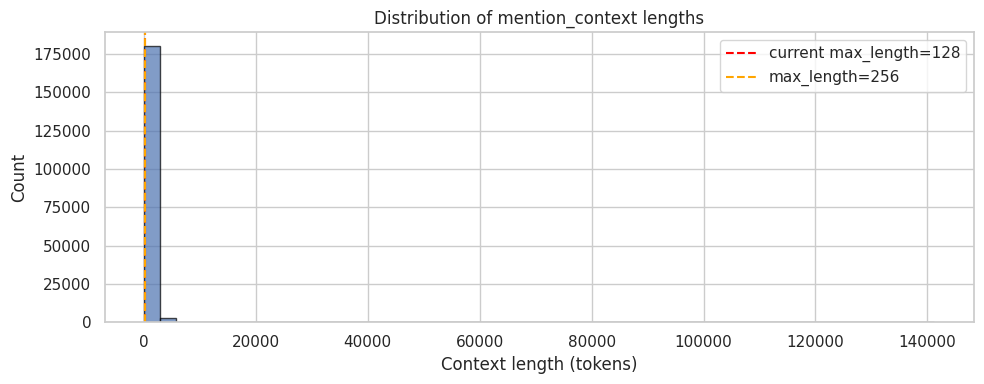

In [20]:
# Context length in tokens
all_mentions["context_len"] = all_mentions["mention_context"].apply(len)

print("Context length (tokens) statistics:")
print(all_mentions["context_len"].describe().to_string())

print("\nPer dataset:")
print(all_mentions.groupby("dataset")["context_len"].agg(["mean", "median", "min", "max"]).round(1))

fig, ax = plt.subplots(figsize=(10, 4))
all_mentions["context_len"].hist(bins=50, ax=ax, edgecolor="black", alpha=0.7)
ax.set_xlabel("Context length (tokens)")
ax.set_ylabel("Count")
ax.set_title("Distribution of mention_context lengths")
ax.axvline(x=128, color="red", linestyle="--", label="current max_length=128")
ax.axvline(x=256, color="orange", linestyle="--", label="max_length=256")
ax.legend()
plt.tight_layout()
plt.show()

## 11. PK Sampling feasibility analysis

For MS Loss we need PK batches: P chains with K mentions each.
Let's see what P and K values are feasible given chain sizes in each dataset.

In [21]:
# For each K value, how many chains (P candidates) are available per dataset?
train_chain_sizes_merged = train_chain_sizes.copy()

k_values = [2, 3, 4, 5]
pk_feasibility = []

for ds in sorted(train_chain_sizes_merged["dataset"].unique()):
    ds_chains = train_chain_sizes_merged[train_chain_sizes_merged["dataset"] == ds]
    row = {"dataset": ds, "total_chains": len(ds_chains)}
    for k in k_values:
        eligible = (ds_chains["chain_size"] >= k).sum()
        row[f"chains_ge_{k}"] = eligible
        row[f"pct_ge_{k}"] = round(eligible / len(ds_chains) * 100, 1)
    pk_feasibility.append(row)

pk_df = pd.DataFrame(pk_feasibility).set_index("dataset")
pk_df

,total_chains,chains_ge_2,pct_ge_2,chains_ge_3,pct_ge_3,chains_ge_4,pct_ge_4,chains_ge_5,pct_ge_5
dataset,,,,,,,,,
CD2CR,3221,426,13.2,196,6.1,125,3.9,89,2.8
CEREC,750,535,71.3,400,53.3,309,41.2,252,33.6
ECBplus,2810,877,31.2,657,23.4,521,18.5,444,15.8
FCC,259,151,58.3,113,43.6,89,34.4,67,25.9
GVC,1158,737,63.6,591,51.0,487,42.1,397,34.3
HyperCoref,5477,5477,100.0,5477,100.0,5468,99.8,3979,72.6
MEANTIME,1522,374,24.6,179,11.8,99,6.5,68,4.5
NIdent,1316,698,53.0,458,34.8,341,25.9,263,20.0
NP4E,332,332,100.0,196,59.0,166,50.0,123,37.0


In [22]:
# Simulate a PK batch: P=16 chains, K=2 mentions each = batch of 32
# How often can we fill this from each dataset's train split?
P, K = 16, 2

print(f"PK sampling simulation: P={P}, K={K} (batch size = {P*K})")
print("="*60)

for ds in sorted(train_chain_sizes_merged["dataset"].unique()):
    ds_chains = train_chain_sizes_merged[
        (train_chain_sizes_merged["dataset"] == ds) &
        (train_chain_sizes_merged["chain_size"] >= K)
    ]
    n_eligible = len(ds_chains)
    n_batches = n_eligible // P if n_eligible >= P else 0
    total_mentions = train_mentions[train_mentions["dataset"] == ds].shape[0]
    print(f"{ds:20s}  eligible chains: {n_eligible:>5,}  possible batches: {n_batches:>5,}  train mentions: {total_mentions:>6,}")

PK sampling simulation: P=16, K=2 (batch size = 32)
CD2CR                 eligible chains:   426  possible batches:    26  train mentions:  4,602
CEREC                 eligible chains:   535  possible batches:    33  train mentions:  3,719
ECBplus               eligible chains:   877  possible batches:    54  train mentions:  8,521
FCC                   eligible chains:   151  possible batches:     9  train mentions:  1,603
GVC                   eligible chains:   737  possible batches:    46  train mentions:  5,299
HyperCoref            eligible chains: 5,477  possible batches:   342  train mentions: 49,777
MEANTIME              eligible chains:   374  possible batches:    23  train mentions:  3,355
NIdent                eligible chains:   698  possible batches:    43  train mentions:  7,178
NP4E                  eligible chains:   332  possible batches:    20  train mentions:  3,375
WECEng                eligible chains: 6,210  possible batches:   388  train mentions: 40,529


## 12. Summary & next steps

Key findings to inform the MS Loss implementation:

1. **Chain sparsity**: What fraction of chains are singletons? What's the minimum viable K?
2. **Context availability**: `mention_context` + `tokens_number_context` provide everything needed for `[E]`/`[/E]` marker insertion
3. **Dataset heterogeneity**: Chain sizes vary dramatically across datasets
4. **PK feasibility**: Which (P, K) combinations are viable across all datasets?

In [ ]:
# Final summary
print("KEY NUMBERS")
print("="*60)
print(f"Total mentions:           {len(all_mentions):>10,}")
print(f"Total chains:             {len(chain_sizes):>10,}")
print(f"Singletons:               {all_mentions['is_singleton'].sum():>10,} ({all_mentions['is_singleton'].mean()*100:.1f}%)")
print(f"Non-singleton chains:     {(chain_sizes['chain_size'] >= 2).sum():>10,}")
print(f"Avg chain size (all):     {chain_sizes['chain_size'].mean():>10.2f}")
print(f"Avg chain size (>=2):     {chain_sizes[chain_sizes['chain_size']>=2]['chain_size'].mean():>10.2f}")
print(f"Median chain size (>=2):  {chain_sizes[chain_sizes['chain_size']>=2]['chain_size'].median():>10.1f}")
print(f"\nTrain split:")
print(f"  Mentions:               {len(train_mentions):>10,}")
print(f"  Chains:                 {len(train_chain_sizes):>10,}")
print(f"  Chains with size >= 2:  {(train_chain_sizes['chain_size'] >= 2).sum():>10,}")
print(f"  Chains with size >= 4:  {(train_chain_sizes['chain_size'] >= 4).sum():>10,}")